<a href="https://colab.research.google.com/github/ayeshaalamexe/cs320-yolov1/blob/main/YOLOv1_PennFudan_CS320.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os
os.makedirs('/content/drive/MyDrive/yolo_project/checkpoints', exist_ok=True)
print("Folder ready")

Folder ready


In [10]:
import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
print("Seed set")

Seed set


In [11]:
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip -O /content/PennFudanPed.zip
!unzip -q -o /content/PennFudanPed.zip -d /content/
!ls /content/PennFudanPed

added-object-list.txt  Annotation  PedMasks  PNGImages	readme.txt


In [14]:
import os, numpy as np, torch
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torch.utils.data import Dataset, DataLoader, random_split

ROOT = '/content/PennFudanPed'
IMG_SIZE = 448
S, B, C = 7, 2, 1   # grid, boxes per cell, classes
print("Imports ready")

Imports ready


In [15]:
class PennFudanDataset(Dataset):
    def __init__(self, root, img_size=448):
        self.root = root
        self.img_size = img_size
        self.imgs = sorted(os.listdir(os.path.join(root, 'PNGImages')))
        self.masks = sorted(os.listdir(os.path.join(root, 'PedMasks')))

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.root, 'PNGImages', self.imgs[idx])).convert('RGB')
        mask = np.array(Image.open(os.path.join(self.root, 'PedMasks', self.masks[idx])))
        W, H = img.size

        # har pedestrian ka alag ID hota hai mask mein (0 = background)
        ids = np.unique(mask)[1:]
        boxes = []
        for i in ids:
            ys, xs = np.where(mask == i)
            x1, x2, y1, y2 = xs.min(), xs.max(), ys.min(), ys.max()
            # (x_center, y_center, w, h), values 0 se 1 ke beech
            boxes.append([(x1 + x2) / 2 / W, (y1 + y2) / 2 / H,
                          (x2 - x1) / W, (y2 - y1) / H])

        img = img.resize((self.img_size, self.img_size))
        img = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        boxes = torch.tensor(boxes, dtype=torch.float32)
        return img, boxes

# har image mein boxes ki tadaad alag hoti hai, isliye custom collate
def collate_fn(batch):
    imgs = torch.stack([b[0] for b in batch])
    boxes = [b[1] for b in batch]
    return imgs, boxes

dataset = PennFudanDataset(ROOT, IMG_SIZE)
print("Total images:", len(dataset))

Total images: 170


In [16]:
g = torch.Generator().manual_seed(42)
n_train = int(0.8 * len(dataset))
train_set, val_set = random_split(dataset, [n_train, len(dataset) - n_train], generator=g)

train_loader = DataLoader(train_set, batch_size=8, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_set, batch_size=8, shuffle=False, collate_fn=collate_fn)

imgs, boxes = next(iter(train_loader))
print("Train size:", len(train_set), "| Val size:", len(val_set))
print("Batch shape:", imgs.shape)
print("Dtype:", imgs.dtype)
print("Boxes in image 0:", boxes[0].shape)

Train size: 136 | Val size: 34
Batch shape: torch.Size([8, 3, 448, 448])
Dtype: torch.float32
Boxes in image 0: torch.Size([2, 4])


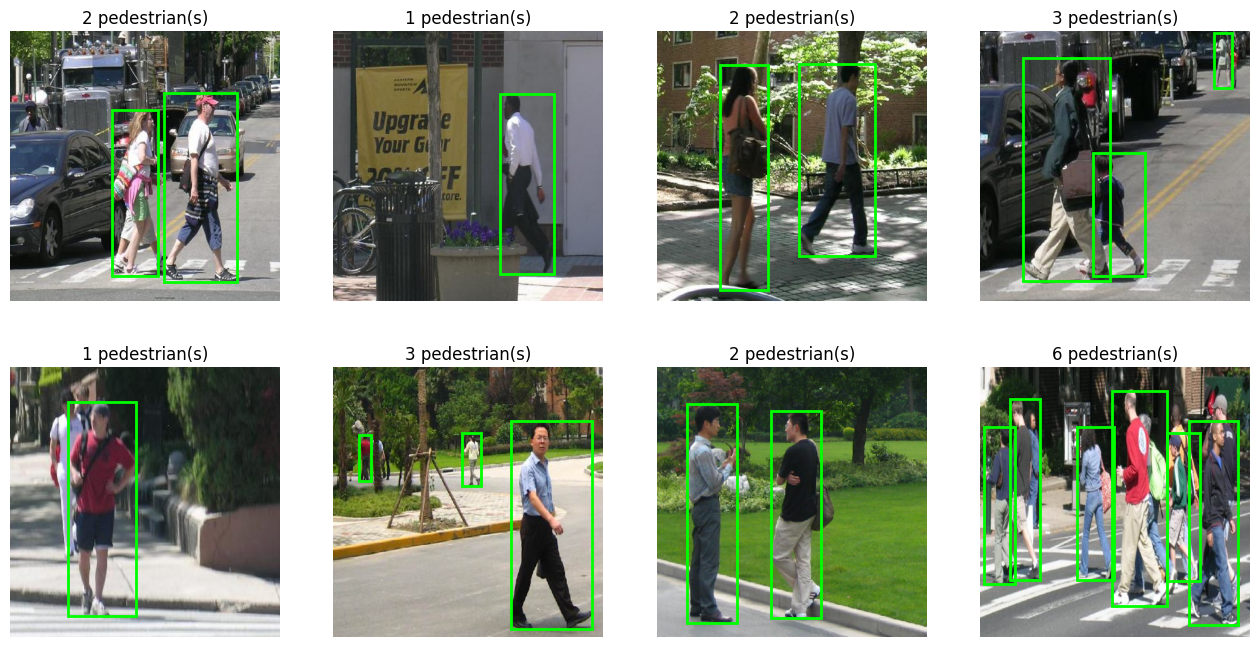

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, img, bx in zip(axes.flat, imgs, boxes):
    ax.imshow(img.permute(1, 2, 0))
    for xc, yc, w, h in bx:
        rect = patches.Rectangle(((xc - w/2) * IMG_SIZE, (yc - h/2) * IMG_SIZE),
                                 w * IMG_SIZE, h * IMG_SIZE,
                                 linewidth=2, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
    ax.set_title(f"{len(bx)} pedestrian(s)")
    ax.axis('off')
plt.show()

In [19]:
!pip install -q torchinfo

In [20]:
import torch.nn as nn
import torchvision
from torchinfo import summary
print("ok")

ok


In [21]:
class YOLOv1(nn.Module):
    def __init__(self, S=7, B=2, C=1):
        super().__init__()
        self.S, self.B, self.C = S, B, C
        resnet = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.DEFAULT)
        # last 2 layers (avgpool, fc) hata do, sirf conv features rakho
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])   # out: 512 x 14 x 14
        self.head = nn.Sequential(
            nn.Conv2d(512, 1024, 3, stride=2, padding=1),   # 14x14 -> 7x7
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.1),
            nn.Conv2d(1024, 1024, 3, padding=1),
            nn.BatchNorm2d(1024),
            nn.LeakyReLU(0.1),
            nn.Flatten(),
            nn.Linear(7 * 7 * 1024, 4096),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.5),
            nn.Linear(4096, S * S * (B * 5 + C)),
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.head(x)
        return x.view(-1, self.S, self.S, self.B * 5 + self.C)

model = YOLOv1(S, B, C).cuda()
x = torch.randn(2, 3, 448, 448).cuda()
print("Output shape:", model(x).shape)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 191MB/s]


Output shape: torch.Size([2, 7, 7, 11])


In [22]:
summary(model, input_size=(1, 3, 448, 448), depth=2,
        col_names=("output_size", "num_params"))

Layer (type:depth-idx)                        Output Shape              Param #
YOLOv1                                        [1, 7, 7, 11]             --
├─Sequential: 1-1                             [1, 512, 14, 14]          --
│    └─Conv2d: 2-1                            [1, 64, 224, 224]         9,408
│    └─BatchNorm2d: 2-2                       [1, 64, 224, 224]         128
│    └─ReLU: 2-3                              [1, 64, 224, 224]         --
│    └─MaxPool2d: 2-4                         [1, 64, 112, 112]         --
│    └─Sequential: 2-5                        [1, 64, 112, 112]         221,952
│    └─Sequential: 2-6                        [1, 128, 56, 56]          1,116,416
│    └─Sequential: 2-7                        [1, 256, 28, 28]          6,822,400
│    └─Sequential: 2-8                        [1, 512, 14, 14]          13,114,368
├─Sequential: 1-2                             [1, 539]                  --
│    └─Conv2d: 2-9                            [1, 1024, 7, 7]   

In [23]:
def encode_targets(boxes_list, S=7, C=1):
    t = torch.zeros(len(boxes_list), S, S, 5 + C)
    for n, bx in enumerate(boxes_list):
        for xc, yc, w, h in bx:
            j = min(int(xc * S), S - 1)   # column
            i = min(int(yc * S), S - 1)   # row
            if t[n, i, j, 4] == 1:        # cell pehle se bhara hai (2 objects, 1 cell)
                continue
            t[n, i, j, 0] = xc * S - j
            t[n, i, j, 1] = yc * S - i
            t[n, i, j, 2] = w
            t[n, i, j, 3] = h
            t[n, i, j, 4] = 1
            t[n, i, j, 5] = 1
    return t

targets = encode_targets(boxes)
print("Target shape:", targets.shape)
print("Objects in batch:", int(targets[..., 4].sum()), "| boxes in labels:", sum(len(b) for b in boxes))

Target shape: torch.Size([8, 7, 7, 6])
Objects in batch: 20 | boxes in labels: 20


In [24]:
def cell_iou(p, t, S=7):
    # p, t: (..., 4) = x, y, w, h. x,y cell ke andar, w,h image ke relative
    pw, ph = p[..., 2].abs() * S, p[..., 3].abs() * S
    tw, th = t[..., 2] * S, t[..., 3] * S
    p1x, p2x = p[..., 0] - pw / 2, p[..., 0] + pw / 2
    p1y, p2y = p[..., 1] - ph / 2, p[..., 1] + ph / 2
    t1x, t2x = t[..., 0] - tw / 2, t[..., 0] + tw / 2
    t1y, t2y = t[..., 1] - th / 2, t[..., 1] + th / 2
    iw = (torch.min(p2x, t2x) - torch.max(p1x, t1x)).clamp(min=0)
    ih = (torch.min(p2y, t2y) - torch.max(p1y, t1y)).clamp(min=0)
    inter = iw * ih
    union = pw * ph + tw * th - inter + 1e-6
    return inter / union

class YOLOLoss(nn.Module):
    def __init__(self, S=7, B=2, C=1, l_coord=5.0, l_noobj=0.5):
        super().__init__()
        self.S, self.B, self.C = S, B, C
        self.l_coord, self.l_noobj = l_coord, l_noobj

    def forward(self, pred, target):
        N = pred.shape[0]
        obj = target[..., 4]                       # N,S,S
        noobj = 1 - obj
        b1, b2 = pred[..., 0:5], pred[..., 5:10]
        iou1 = cell_iou(b1[..., :4], target[..., :4], self.S)
        iou2 = cell_iou(b2[..., :4], target[..., :4], self.S)
        r2 = (iou2 > iou1).float().unsqueeze(-1)   # 1 => box 2 zimmedar
        resp = r2 * b2 + (1 - r2) * b1             # N,S,S,5
        best_iou = torch.max(iou1, iou2).detach()

        # 1) center x,y
        l_xy = (obj.unsqueeze(-1) * (resp[..., 0:2] - target[..., 0:2]) ** 2).sum()
        # 2) w,h (sqrt; sign + eps se NaN nahi aata)
        pwh = torch.sign(resp[..., 2:4]) * torch.sqrt(resp[..., 2:4].abs() + 1e-6)
        twh = torch.sqrt(target[..., 2:4])
        l_wh = (obj.unsqueeze(-1) * (pwh - twh) ** 2).sum()
        # 3) confidence, object wale cells
        l_obj = (obj * (resp[..., 4] - best_iou) ** 2).sum()
        # 4) confidence, khali cells (dono boxes)
        l_noobj = (noobj * (b1[..., 4] ** 2 + b2[..., 4] ** 2)).sum()
        # 5) class
        l_cls = (obj.unsqueeze(-1) * (pred[..., 10:] - target[..., 5:]) ** 2).sum()

        total = (self.l_coord * (l_xy + l_wh) + l_obj
                 + self.l_noobj * l_noobj + l_cls) / N
        parts = dict(xy=l_xy.item() / N, wh=l_wh.item() / N, obj=l_obj.item() / N,
                     noobj=l_noobj.item() / N, cls=l_cls.item() / N)
        return total, parts

criterion = YOLOLoss(S, B, C)
print("Loss ready")

Loss ready


In [25]:
model.train()
with torch.no_grad():
    pred = model(imgs.cuda())
    loss, parts = criterion(pred, targets.cuda())
print("Pred shape:", pred.shape)
print("First loss:", loss.item())
print("Parts:", {k: round(v, 3) for k, v in parts.items()})

Pred shape: torch.Size([8, 7, 7, 11])
First loss: 27.802732467651367
Parts: {'xy': 1.557, 'wh': 2.896, 'obj': 0.28, 'noobj': 5.099, 'cls': 2.709}


In [34]:
import torch.optim as optim

torch.manual_seed(42)
model = YOLOv1(S, B, C).cuda()
for m in model.modules():
    if isinstance(m, nn.Dropout):
        m.p = 0.0          # sirf is test ke liye dropout band
criterion = YOLOLoss(S, B, C)
opt = optim.Adam(model.parameters(), lr=1e-4)

x_b, t_b = imgs.cuda(), targets.cuda()
history = []
model.train()
for step in range(300):
    pred = model(x_b)
    loss, parts = criterion(pred, t_b)
    opt.zero_grad()
    loss.backward()
    opt.step()
    history.append(loss.item())
    if step % 30 == 0 or step == 299:
        print(f"step {step:3d} | loss {loss.item():.4f} | " +
              " ".join(f"{k}={v:.3f}" for k, v in parts.items()))

step   0 | loss 24.4121 | xy=1.586 wh=2.421 obj=0.243 noobj=3.039 cls=2.614
step  30 | loss 2.0670 | xy=0.087 wh=0.190 obj=0.264 noobj=0.793 cls=0.025
step  60 | loss 0.7417 | xy=0.010 wh=0.067 obj=0.216 noobj=0.270 cls=0.003
step  90 | loss 0.7867 | xy=0.008 wh=0.138 obj=0.008 noobj=0.100 cls=0.001
step 120 | loss 0.3270 | xy=0.001 wh=0.060 obj=0.008 noobj=0.031 cls=0.000
step 150 | loss 0.6087 | xy=0.019 wh=0.047 obj=0.022 noobj=0.500 cls=0.005
step 180 | loss 0.1366 | xy=0.002 wh=0.014 obj=0.018 noobj=0.074 cls=0.001
step 210 | loss 0.0101 | xy=0.000 wh=0.000 obj=0.004 noobj=0.006 cls=0.000
step 240 | loss 0.0005 | xy=0.000 wh=0.000 obj=0.000 noobj=0.000 cls=0.000
step 270 | loss 0.0000 | xy=0.000 wh=0.000 obj=0.000 noobj=0.000 cls=0.000
step 299 | loss 0.0000 | xy=0.000 wh=0.000 obj=0.000 noobj=0.000 cls=0.000


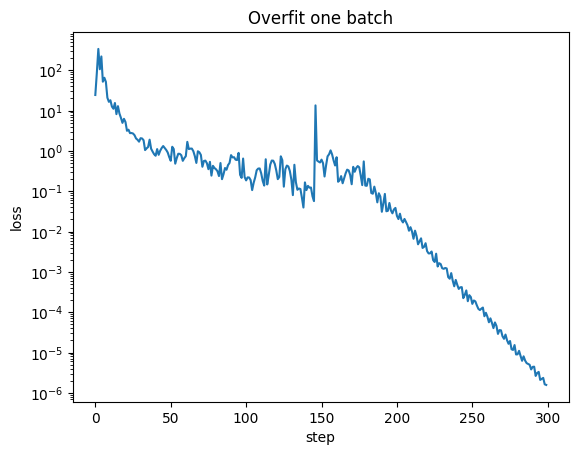

In [35]:
plt.plot(history)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Overfit one batch")
plt.yscale("log")
plt.show()

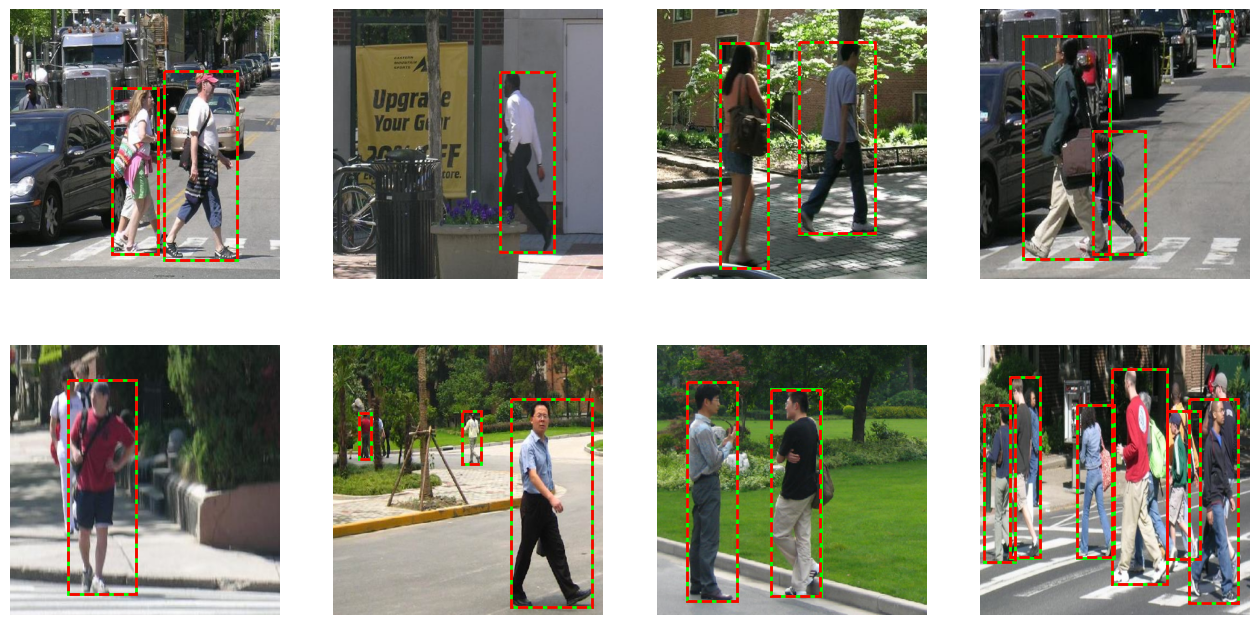

In [36]:
model.eval()
with torch.no_grad():
    pred = model(x_b).cpu()

def decode(p, thr=0.3, S=7):
    out = []
    for i in range(S):
        for j in range(S):
            for b in range(2):
                x, y, w, h, c = p[i, j, b*5:b*5+5]
                if c > thr:
                    out.append(((j + x) / S, (i + y) / S, w.abs(), h.abs(), c))
    return out

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, img, bx, p in zip(axes.flat, imgs, boxes, pred):
    ax.imshow(img.permute(1, 2, 0))
    for xc, yc, w, h in bx:   # asli = green
        ax.add_patch(patches.Rectangle(((xc-w/2)*IMG_SIZE, (yc-h/2)*IMG_SIZE),
                     w*IMG_SIZE, h*IMG_SIZE, lw=2, ec='lime', fc='none'))
    for xc, yc, w, h, c in decode(p):   # predicted = red
        ax.add_patch(patches.Rectangle(((xc-w/2)*IMG_SIZE, (yc-h/2)*IMG_SIZE),
                     w*IMG_SIZE, h*IMG_SIZE, lw=2, ec='red', fc='none', ls='--'))
    ax.axis('off')
plt.show()

In [38]:
def run_epoch(model, loader, criterion, opt=None, scaler=None):
    train = opt is not None
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, bxs in loader:
            xb = xb.cuda()
            tb = encode_targets(bxs, S, C).cuda()
            with torch.autocast("cuda", dtype=torch.float16):
                pred = model(xb)
            loss, _ = criterion(pred.float(), tb)
            if train:
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
            total += loss.item() * xb.size(0)
            n += xb.size(0)
    return total / n
print("ok")

ok


In [40]:
torch.manual_seed(42)
model = YOLOv1(S, B, C).cuda()
criterion = YOLOLoss(S, B, C)
opt = optim.Adam(model.parameters(), lr=1e-4)
scaler = torch.cuda.amp.GradScaler()

train_hist, val_hist = [], []
best = 1e9
for ep in range(15):
    tr = run_epoch(model, train_loader, criterion, opt, scaler)
    va = run_epoch(model, val_loader, criterion)
    train_hist.append(tr); val_hist.append(va)
    if va < best:
        best = va
        torch.save(model.state_dict(), '/content/drive/MyDrive/yolo_project/checkpoints/baseline_best.pt')
    print(f"epoch {ep+1:2d} | train {tr:.3f} | val {va:.3f}")

/tmp/ipykernel_1181/1329387040.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


epoch  1 | train 57.043 | val 24.974
epoch  2 | train 52.121 | val 57.771
epoch  3 | train 21.715 | val 37.744
epoch  4 | train 11.794 | val 13.528
epoch  5 | train 8.603 | val 8.579
epoch  6 | train 9.333 | val 5.690
epoch  7 | train 6.605 | val 3.270
epoch  8 | train 6.611 | val 4.950
epoch  9 | train 5.254 | val 11.541
epoch 10 | train 4.803 | val 7.142
epoch 11 | train 4.896 | val 3.102
epoch 12 | train 4.340 | val 2.978
epoch 13 | train 3.921 | val 3.635
epoch 14 | train 3.776 | val 2.622
epoch 15 | train 3.171 | val 2.759


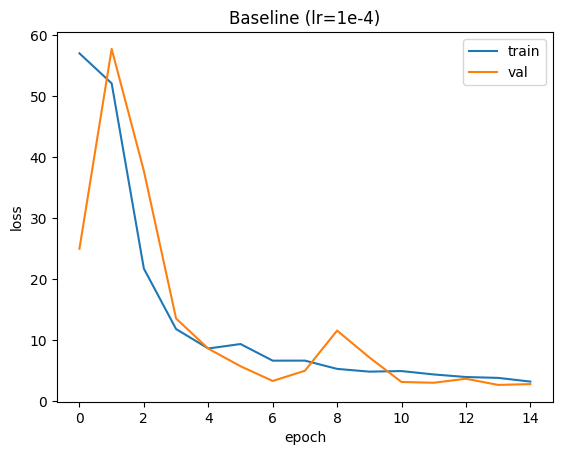

In [41]:
plt.plot(train_hist, label="train"); plt.plot(val_hist, label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Baseline (lr=1e-4)")
plt.show()